# LightCyto — saved-model quantitative XAI
**Evaluation only; no training.** Attach **My_final_model** (full output shown in your screenshot) and the original **SIPaKMeD** dataset. Enable GPU, then Run All.

The source resolver searches both ordinary and nested Kaggle input mounts for `experiment.json`, `manifest.csv`, and `seed_42/student/best.pt`, preferring paths matching `My_final_model`. No guessed dataset slug is required. It rejects ambiguous matches.

This notebook evaluates the **global TinyViT student** using the exact architecture definitions from `my-final (2).ipynb`. PPO routing and local fusion are not evaluated. It preserves saved split membership and class order; it never creates a new split.

Default: 100 validation images, 20 perturbation intervals, 3 random controls per image. Run the pilot before fixing the protocol for a full evaluation. Insertion/deletion are perturbation-dependent faithfulness diagnostics, not anatomical validation. No SSIM or parameter-randomization claims are made.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json, math, hashlib, shutil, warnings, time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
try:
    import timm
except ImportError as exc:
    raise ImportError("Install the same timm version as your training notebook, then restart and Run All.") from exc
from IPython.display import display, FileLink

# Leave blank for discovery. Set exact folders only if multiple matches are found.
MODEL_ROOT = ""
MODEL_HINT = "My_final_model"
DATASET_ROOT = ""
SEED = 42
SPLIT = "val"
MAX_IMAGES = 100          # None = all images of the selected split
STEPS = 20
PERTURB_BATCH = 8
RANDOM_REPEATS = 3
SAMPLE_SEED = 2026
OUTPUT_ROOT = Path('/kaggle/working/lightcyto_quantitative_xai')
assert SPLIT in ('val', 'test')
assert STEPS >= 2 and PERTURB_BATCH >= 1 and RANDOM_REPEATS >= 1
assert MAX_IMAGES is None or MAX_IMAGES > 0


In [2]:
def file_hash(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

def canonical(s): return ''.join(c for c in str(s).lower() if c.isalnum())

def resolve_model():
    def complete(p):
        return all((p/q).is_file() for q in ('experiment.json','manifest.csv',f'seed_{SEED}/student/best.pt'))
    if MODEL_ROOT:
        p=Path(MODEL_ROOT)
        if not complete(p): raise FileNotFoundError(f'Incomplete model folder: {p}')
        return p
    candidates=sorted({p.parent for p in Path('/kaggle/input').rglob('experiment.json') if complete(p.parent)})
    preferred=[p for p in candidates if canonical(MODEL_HINT) in canonical(p)]
    candidates=preferred or candidates
    if len(candidates)!=1:
        raise FileNotFoundError('Set MODEL_ROOT to the full saved output folder. Complete candidates: '+str(candidates))
    return candidates[0]

root=resolve_model()
contract=json.loads((root/'experiment.json').read_text())
CLASSES=tuple(contract['classes'])
STUDENT_NAME=contract['student']
if len(CLASSES)!=5 or STUDENT_NAME!='tiny_vit_5m_224.dist_in22k_ft_in1k':
    raise ValueError('This notebook targets the five-class TinyViT model from my-final (2).ipynb.')
CFG=SimpleNamespace(**contract['config'])
if CFG.image_size!=224: raise ValueError('Expected saved 224-pixel TinyViT configuration.')
checkpoint_path=root/f'seed_{SEED}'/'student'/'best.pt'
checkpoint=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
if checkpoint.get('contract')!=contract['contract_hash']:
    raise ValueError('Checkpoint and experiment contract do not match.')
receipt=root/f'seed_{SEED}'/'student'/'complete.json'
if receipt.exists():
    expected=json.loads(receipt.read_text()).get('best_sha256')
    if expected and expected!=file_hash(checkpoint_path): raise ValueError('Checkpoint checksum mismatch.')
training_runtime=contract.get('runtime',{})
if training_runtime.get('timm')!=timm.__version__:
    warnings.warn(f"Training timm={training_runtime.get('timm')}; current timm={timm.__version__}. Use the training environment for reproducibility.")
required={'im_'+c for c in CLASSES}
def is_dataset(p):
    return p.is_dir() and required <= {x.name for x in p.iterdir() if x.is_dir()}
if DATASET_ROOT:
    dataset=Path(DATASET_ROOT)
    if not is_dataset(dataset): raise FileNotFoundError('DATASET_ROOT must contain all five im_* class folders.')
else:
    candidates=sorted({p.parent for p in Path('/kaggle/input').rglob('im_Dyskeratotic') if is_dataset(p.parent)})
    if len(candidates)!=1: raise FileNotFoundError('Set DATASET_ROOT. Candidates: '+str(candidates))
    dataset=candidates[0]
manifest=pd.read_csv(root/'manifest.csv',dtype={'sample_id':str})
required_columns={'sample_id','relative_path','class_name','label','split','group_id','file_sha256'}
if not required_columns <= set(manifest): raise ValueError('Saved manifest is missing required identity/split columns.')
if manifest.sample_id.duplicated().any(): raise ValueError('Duplicate sample IDs.')
if manifest.groupby('group_id').split.nunique().max()>1: raise ValueError('Saved groups overlap splits.')
for row in manifest.itertuples():
    if CLASSES[int(row.label)]!=row.class_name: raise ValueError('Class order mismatch.')
frame=manifest[manifest.split==SPLIT].copy().reset_index(drop=True)
if MAX_IMAGES is not None and len(frame)>MAX_IMAGES:
    frame=frame.sample(MAX_IMAGES,random_state=SAMPLE_SEED).reset_index(drop=True)
if frame.empty: raise ValueError('Selected split is empty.')
frame['path']=[str(dataset/p) for p in frame.relative_path]
for row in frame.itertuples():
    p=Path(row.path)
    if not p.is_file(): raise FileNotFoundError(p)
    if file_hash(p)!=row.file_sha256: raise ValueError('Image checksum mismatch: '+str(p))
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
frame.to_csv(OUTPUT_ROOT/'evaluated_manifest.csv',index=False)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type=='cpu': warnings.warn('GPU recommended: perturbation evaluation can be slow on CPU.')
print('Model:',root,'\nCheckpoint:',checkpoint_path,'\nImages:',dataset,'\nSplit:',SPLIT,'count:',len(frame),'device:',device)
display(frame.groupby('class_name').size().rename('evaluated_images').to_frame())


/tmp/ipykernel_23/601268374.py:41: UserWarning: Training timm=1.0.22; current timm=1.0.29. Use the training environment for reproducibility.
  warnings.warn(f"Training timm={training_runtime.get('timm')}; current timm={timm.__version__}. Use the training environment for reproducibility.")


Model: /kaggle/input/datasets/anindobaruabijoy/my-final-model/lightcyto_tinyvit_end_to_end 
Checkpoint: /kaggle/input/datasets/anindobaruabijoy/my-final-model/lightcyto_tinyvit_end_to_end/seed_42/student/best.pt 
Images: /kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed 
Split: val count: 100 device: cuda


,evaluated_images
class_name,
Dyskeratotic,20
Koilocytotic,25
Metaplastic,16
Parabasal,21
Superficial-Intermediate,18


## Exact student architecture and deterministic preprocessing
Copied from your supplied notebook. The student constructor uses `pretrained=False`; trained weights come from your checkpoint.

In [3]:
def letterbox(im,size):
    w,h=im.size; scale=min(size/w,size/h)
    nw,nh=max(1,round(w*scale)),max(1,round(h*scale)); left=(size-nw)//2; top=(size-nh)//2
    canvas=Image.new('RGB',(size,size),(255,255,255))
    canvas.paste(im.resize((nw,nh),Image.Resampling.BILINEAR),(left,top))
    rgb=torch.from_numpy(np.asarray(canvas).copy()).permute(2,0,1).float()/255.
    valid=torch.zeros(1,size,size); valid[:,top:top+nh,left:left+nw]=1.
    meta=(left,top,nw,nh,w,h)
    return rgb,valid,meta

def morphology_proxies(rgb,valid):
    # Image-derived proxies, not ground-truth segmentation or verified anatomy.
    gray=.299*rgb[:,0:1]+.587*rgb[:,1:2]+.114*rgb[:,2:3]
    sat=rgb.amax(1,keepdim=True)-rgb.amin(1,keepdim=True)
    nucleus=(1-gray).clamp_min(.01).pow(2)
    cyto=(sat+.03)*(gray+.10)
    dx=F.pad((gray[:,:,:,1:]-gray[:,:,:,:-1]).abs(),(0,1,0,0))
    dy=F.pad((gray[:,:,1:,:]-gray[:,:,:-1,:]).abs(),(0,0,0,1))
    interior=(F.avg_pool2d(valid,5,1,2)>.99).to(rgb.dtype)
    edge=(dx+dy+.005)*interior
    prior=torch.cat([nucleus,cyto,edge],1)*valid
    return prior.clamp_min(1e-8)

class ConvGN(nn.Sequential):
    def __init__(self,a,b,k=1,s=1,groups=1,act=True):
        gn=math.gcd(8,b)
        super().__init__(nn.Conv2d(a,b,k,s,k//2,groups=groups,bias=False),nn.GroupNorm(gn,b),
                         nn.SiLU(inplace=False) if act else nn.Identity())

class QueryMorphologyAttention(nn.Module):
    """Three learned morphology queries, with image-derived proxy biases.

    Uses original encoder resolution. The scorer and four attention heads are learned;
    proxy maps are weak cues, not nucleus/cytoplasm ground-truth masks.
    """
    def __init__(self, c, heads):
        super().__init__()
        self.heads, self.c = heads, c
        self.score = nn.Sequential(nn.Conv2d(c, max(4,c//4), 1), nn.GELU(), nn.Conv2d(max(4,c//4),3,1))
        self.prior_strength = nn.Parameter(torch.zeros(3))
        self.queries = nn.Parameter(torch.randn(3,c)*.02)
        self.position = nn.Linear(2,c,bias=False)
        self.token_norm = nn.LayerNorm(c)
        self.query_norm = nn.LayerNorm(c)
        self.cross = nn.MultiheadAttention(c,heads,batch_first=True,dropout=0.)
        self.region_norm = nn.LayerNorm(c)
        self.channel_mix = nn.Linear(3*c,c)
    def forward(self, f, prior, valid):
        b,c,h,w = f.shape
        mask = F.adaptive_avg_pool2d(valid,(h,w)).flatten(1) > .05
        if not mask.any(1).all(): raise ValueError('No valid image tokens')
        yy,xx = torch.meshgrid(torch.linspace(-1,1,h,device=f.device,dtype=f.dtype),
                               torch.linspace(-1,1,w,device=f.device,dtype=f.dtype),indexing='ij')
        xy = torch.stack((xx,yy),-1).reshape(1,h*w,2)
        tokens = f.flatten(2).transpose(1,2)
        keys = self.token_norm(tokens+self.position(xy))
        p = F.adaptive_avg_pool2d(prior,(h,w)).clamp_min(1e-8)
        bias = (self.score(f)+F.softplus(self.prior_strength)[None,:,None,None]*p.log()).flatten(2)
        bias = bias.masked_fill(~mask[:,None,:],-1e4)
        bias = bias[:,None].expand(-1,self.heads,-1,-1).reshape(b*self.heads,3,h*w)
        queries = self.query_norm(self.queries)[None].expand(b,-1,-1)
        regions,weights = self.cross(queries,keys,tokens,attn_mask=bias,need_weights=True)
        pooled = (tokens*mask[:,:,None]).sum(1)/mask.sum(1,keepdim=True)
        z = pooled + .25*self.channel_mix(self.region_norm(regions).flatten(1))
        return z,weights.reshape(b,3,h,w)

class Student(nn.Module):
    def __init__(self,pretrained=False):
        super().__init__()
        self.backbone=timm.create_model(STUDENT_NAME,pretrained=pretrained,num_classes=0)
        self.backbone.head=nn.Identity()
        self.register_buffer('mean',torch.tensor(self.backbone.pretrained_cfg['mean']).view(1,3,1,1))
        self.register_buffer('std',torch.tensor(self.backbone.pretrained_cfg['std']).view(1,3,1,1))
        self.projection=ConvGN(self.backbone.num_features,CFG.feature_dim)
        self.attention=QueryMorphologyAttention(CFG.feature_dim,CFG.attention_heads)
        self.norm=nn.LayerNorm(CFG.feature_dim)
        self.head=nn.Sequential(nn.Dropout(.15),nn.Linear(CFG.feature_dim,5))
    def forward(self,rgb,valid):
        f=self.backbone.forward_features((rgb-self.mean.to(rgb))/self.std.to(rgb))
        if f.ndim!=4:raise ValueError('TinyViT must return NCHW features: '+str(f.shape))
        z,maps=self.attention(self.projection(f),morphology_proxies(rgb,valid),valid)
        z=self.norm(z);return z,self.head(z),maps

model=Student(pretrained=False).to(device)
model.load_state_dict(checkpoint['model'],strict=True)
for module in model.modules():
    if hasattr(module,'attention_bias_cache'): module.attention_bias_cache.clear()
model.eval()
del checkpoint
print('Loaded trained student:',sum(p.numel() for p in model.parameters()),'parameters')


Loaded trained student: 5404831 parameters


## Perturbation protocol
Fix the target to each image's original predicted class. Rank valid pixels once using the original map. Change all RGB channels together; preserve letterbox padding. The reference image replaces valid pixels with their mean RGB. The model recomputes its cues for each perturbed input.

Compare the three learned query maps, their mean, the three raw cue maps, and random ordering. Random repeats are averaged within each image. Raw cues are construction-related controls, not independent anatomical ground truth. Record misclassified images too; do not select only visually attractive successes.

In [4]:
@torch.inference_mode()
def probabilities(images,valid,target):
    out=[]
    for chunk in images.split(PERTURB_BATCH):
        logits=model(chunk,valid.expand(len(chunk),-1,-1,-1))[1]
        out.append(logits.float().softmax(1)[:,target].cpu().numpy())
    return np.concatenate(out)

@torch.inference_mode()
def curves_for(rgb,valid,scores,target):
    ids=torch.where(valid[0,0].flatten()>.5)[0]
    if not len(ids): raise ValueError('No valid pixels.')
    ordering=ids[torch.argsort(scores.flatten()[ids],descending=True,stable=True)]
    counts=np.unique(np.rint(np.linspace(0,len(ids),STEPS+1)).astype(int))
    fractions=counts/len(ids)
    flat=rgb.flatten(2)
    baseline=flat.clone()
    baseline[:,:,ids]=flat[:,:,ids].mean(2,keepdim=True)
    baseline=baseline.reshape_as(rgb)
    insertion=[]; deletion=[]
    for offset in range(0,len(counts),PERTURB_BATCH):
        current=counts[offset:offset+PERTURB_BATCH]
        mask=torch.zeros(len(current),rgb.shape[-2]*rgb.shape[-1],device=device)
        for j,count in enumerate(current): mask[j,ordering[:int(count)]]=1
        mask=mask.reshape(-1,1,*rgb.shape[-2:])
        insertion.extend(probabilities(baseline+mask*(rgb-baseline),valid,target))
        deletion.extend(probabilities(rgb+mask*(baseline-rgb),valid,target))
    insertion=np.asarray(insertion); deletion=np.asarray(deletion)
    if not np.isfinite(insertion).all() or not np.isfinite(deletion).all():
        raise ValueError('Non-finite prediction probabilities.')
    if not np.allclose([insertion[0],insertion[-1]],[deletion[-1],deletion[0]],atol=1e-4):
        raise ValueError('Perturbation endpoints disagree.')
    return fractions,insertion,deletion

def auc(y,x):
    integrate=getattr(np,'trapezoid',None)
    if integrate is None: integrate=np.trapz
    return float(integrate(y,x))

protocol={
    'scope':'Global student only, excludes PPO/local fusion',
    'checkpoint':str(checkpoint_path),'checkpoint_sha256':file_hash(checkpoint_path),
    'experiment_contract':contract['contract_hash'],'split':SPLIT,'seed':SEED,
    'images':len(frame),'sample_seed':SAMPLE_SEED,'steps':STEPS,'random_repeats':RANDOM_REPEATS,
    'sample_ids':frame.sample_id.tolist(),
    'baseline':'Per-image mean valid RGB; padding unchanged',
    'target':'Original predicted class, fixed',
    'ranking':'Original explanation, fixed, descending; stable ties',
    'cue_handling':'Recomputed on perturbed input',
    'runtime':{'torch':str(torch.__version__),'timm':timm.__version__,'numpy':np.__version__},
    'sd_definition':'Across evaluated images; not seed SD or confidence interval',
    'limitations':'Perturbation-specific diagnostics; no anatomical, SSIM, or parameter-randomization validation'
}
protocol_path=OUTPUT_ROOT/'protocol.json'
if protocol_path.exists() and json.loads(protocol_path.read_text())!=protocol:
    raise ValueError('Output folder has a different protocol. Choose a new OUTPUT_ROOT.')
protocol_path.write_text(json.dumps(protocol,indent=2))
(OUTPUT_ROOT/'per_image').mkdir(exist_ok=True)


In [5]:
started=time.monotonic()
for index,row in enumerate(frame.itertuples(index=False)):
    # Resume only completed images under the identical recorded protocol.
    result_file=OUTPUT_ROOT/'per_image'/(hashlib.sha256(row.sample_id.encode()).hexdigest()+'.json')
    if result_file.exists(): continue
    with Image.open(row.path) as image:
        rgb,valid,_=letterbox(image.convert('RGB'),CFG.image_size)
    rgb=rgb[None].to(device); valid=valid[None].to(device)
    with torch.inference_mode():
        _,logits,maps=model(rgb,valid)
        p=logits.float().softmax(1); target=int(p.argmax(1).item())
        attention=F.interpolate(maps.float(),size=rgb.shape[-2:],mode='bilinear',align_corners=False)[0]
        cues=morphology_proxies(rgb,valid)[0]
    explanations={'attention_mean':attention.mean(0)}
    for q,name in enumerate(('darkness','colour','boundary')):
        explanations['attention_'+name]=attention[q]
        explanations['cue_'+name]=cues[q]
    g=torch.Generator().manual_seed(int(hashlib.sha256(row.sample_id.encode()).hexdigest()[:8],16))
    for repeat in range(RANDOM_REPEATS):
        explanations[f'random_{repeat}']=torch.rand(rgb.shape[-2:],generator=g).to(device)
    rows=[]; curves=[]
    for method,scores in explanations.items():
        x,ins,dele=curves_for(rgb,valid,scores,target)
        rows.append({'sample_id':row.sample_id,'group_id':row.group_id,'true_class':int(row.label),
            'target_class':target,'correct':target==int(row.label),'original_confidence':float(p[0,target]),
            'method':method,'insertion_auc':auc(ins,x),'deletion_auc':auc(dele,x)})
        for fraction,i,d in zip(x,ins,dele):
            curves.append({'sample_id':row.sample_id,'method':method,'fraction':float(fraction),
                'insertion':float(i),'deletion':float(d)})
    tmp=result_file.with_suffix('.tmp')
    tmp.write_text(json.dumps({'metrics':rows,'curves':curves},allow_nan=False)); tmp.replace(result_file)
    if (index+1)%5==0 or index+1==len(frame):
        print(f'{index+1}/{len(frame)} images processed; elapsed {(time.monotonic()-started)/60:.1f} min',flush=True)
print('Evaluation finished. Run export cell next.')


5/100 images processed; elapsed 0.2 min
10/100 images processed; elapsed 0.3 min
15/100 images processed; elapsed 0.3 min
20/100 images processed; elapsed 0.4 min
25/100 images processed; elapsed 0.5 min
30/100 images processed; elapsed 0.6 min
35/100 images processed; elapsed 0.6 min
40/100 images processed; elapsed 0.7 min
45/100 images processed; elapsed 0.8 min
50/100 images processed; elapsed 0.9 min
55/100 images processed; elapsed 0.9 min
60/100 images processed; elapsed 1.0 min
65/100 images processed; elapsed 1.1 min
70/100 images processed; elapsed 1.2 min
75/100 images processed; elapsed 1.3 min
80/100 images processed; elapsed 1.3 min
85/100 images processed; elapsed 1.4 min
90/100 images processed; elapsed 1.5 min
95/100 images processed; elapsed 1.6 min
100/100 images processed; elapsed 1.7 min
Evaluation finished. Run export cell next.


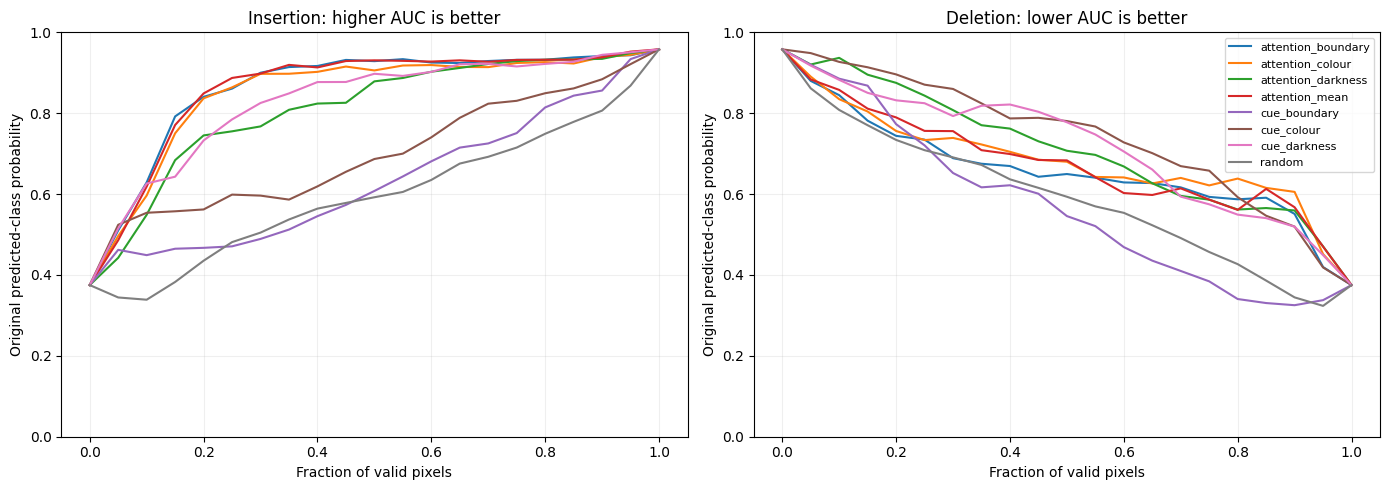

,comparison_method,images,insertion_auc_mean,insertion_auc_image_sd,deletion_auc_mean,deletion_auc_image_sd
0,attention_boundary,100,0.8645,0.1441,0.6616,0.2290
1,attention_colour,100,0.8525,0.1488,0.6849,0.2357
2,attention_darkness,100,0.8123,0.1743,0.7123,0.2215
3,attention_mean,100,0.8635,0.1438,0.6775,0.2277
4,cue_boundary,100,0.6336,0.2897,0.5712,0.2667
5,cue_colour,100,0.7003,0.2225,0.7431,0.2112
6,cue_darkness,100,0.8296,0.1652,0.7164,0.2006
7,random,100,0.5975,0.2916,0.5916,0.2944


/kaggle/working/lightcyto_quantitative_xai.zip

Download: /kaggle/working/lightcyto_quantitative_xai.zip


In [6]:
metric_rows=[]; curve_rows=[]
for sample_id in frame.sample_id:
    path=OUTPUT_ROOT/'per_image'/(hashlib.sha256(sample_id.encode()).hexdigest()+'.json')
    record=json.loads(path.read_text())
    metric_rows.extend(record['metrics']); curve_rows.extend(record['curves'])
metrics=pd.DataFrame(metric_rows); curves=pd.DataFrame(curve_rows)
metrics.to_csv(OUTPUT_ROOT/'per_image_metrics.csv',index=False)
curves.to_csv(OUTPUT_ROOT/'perturbation_curves.csv',index=False)
metrics['comparison_method']=metrics.method.where(~metrics.method.str.startswith('random_'),'random')
per_image=metrics.groupby(['sample_id','comparison_method'],as_index=False)[['insertion_auc','deletion_auc']].mean()
summary=per_image.groupby('comparison_method').agg(images=('sample_id','nunique'),
    insertion_auc_mean=('insertion_auc','mean'),insertion_auc_image_sd=('insertion_auc','std'),
    deletion_auc_mean=('deletion_auc','mean'),deletion_auc_image_sd=('deletion_auc','std')).reset_index()
summary.to_csv(OUTPUT_ROOT/'summary.csv',index=False)
reference=per_image[per_image.comparison_method=='random'].drop(columns='comparison_method').rename(
    columns={'insertion_auc':'random_insertion','deletion_auc':'random_deletion'})
paired=per_image.merge(reference,on='sample_id',validate='many_to_one')
paired['insertion_gain_vs_random']=paired.insertion_auc-paired.random_insertion
paired['deletion_gain_vs_random']=paired.random_deletion-paired.deletion_auc
paired.to_csv(OUTPUT_ROOT/'paired_random_comparison.csv',index=False)
# Interpolate each individual curve to a common grid, then average random repeats
# within images before computing the across-image mean.
grid=np.linspace(0,1,STEPS+1); plot_rows=[]
for (sid,method),part in curves.groupby(['sample_id','method']):
    part=part.sort_values('fraction'); family='random' if method.startswith('random_') else method
    for x,i,d in zip(grid,np.interp(grid,part.fraction,part.insertion),np.interp(grid,part.fraction,part.deletion)):
        plot_rows.append({'sample_id':sid,'method':family,'fraction':x,'insertion':i,'deletion':d})
plot_data=pd.DataFrame(plot_rows).groupby(['sample_id','method','fraction'],as_index=False)[['insertion','deletion']].mean()
mean_curves=plot_data.groupby(['method','fraction'],as_index=False)[['insertion','deletion']].mean()
mean_curves.to_csv(OUTPUT_ROOT/'mean_curves.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for method,part in mean_curves.groupby('method'):
    axes[0].plot(part.fraction,part.insertion,label=method)
    axes[1].plot(part.fraction,part.deletion,label=method)
axes[0].set_title('Insertion: higher AUC is better'); axes[1].set_title('Deletion: lower AUC is better')
for ax in axes:
    ax.set(xlabel='Fraction of valid pixels',ylabel='Original predicted-class probability',ylim=(0,1))
    ax.grid(alpha=.2)
axes[1].legend(fontsize=8); fig.tight_layout()
for extension in ('png','pdf','svg'): fig.savefig(OUTPUT_ROOT/f'insertion_deletion.{extension}',dpi=300)
plt.show(); plt.close(fig)
display(summary.round(4))
archive=shutil.make_archive(str(OUTPUT_ROOT),'zip',root_dir=str(OUTPUT_ROOT))
display(FileLink(archive))
print('Download:',archive)


## Reporting
Report the split, number of images, checkpoint/seed, target definition, reference image, pixel ordering, intervals, and controls alongside AUC. A positive paired gain over random is desirable, but do not claim significance from mean differences alone. Images can share source groups; confidence intervals would need to account for this clustering.

The default pilot is exploratory validation evidence. For a prespecified full-split evaluation, set `MAX_IMAGES=None` and select a **new output directory**. Test results must not guide explanation settings or checkpoint selection. This evaluates only the attached seed; it does not establish three-seed stability.

Your trained checkpoint and Kaggle-mounted images were unavailable in the authoring environment. Notebook structure and Python syntax were checked; actual metrics must be generated on Kaggle.